# 📂 Dia 6 — File I/O com Pandas: CSV, JSON e Excel

**Fase 1 — Python Basics** · Data: 2026-10-19 · Autor: Gutemberg Rapôso

> *"Dados que não podem ser lidos ou salvos de forma confiável não servem para nada."*

Neste notebook pratico **leitura e escrita de arquivos** com pandas usando **datasets públicos reais**
(`seaborn.load_dataset()`): `titanic`, `tips` e `penguins`.

## 🎯 Introdução

Quase todo projeto de Ciência de Dados começa e termina com **I/O (entrada/saída)**: lemos dados brutos
de algum lugar e salvamos resultados para outra pessoa (ou outro sistema) consumir.

**Objetivos de aprendizagem:**

1. Ler e escrever **CSV** com controle de separador, encoding, tipos e valores ausentes.
2. Trabalhar com **JSON**, incluindo JSON **aninhado** e normalização com `pd.json_normalize`.
3. Ler e escrever **Excel** (`.xlsx`) com múltiplas abas via `openpyxl`.
4. Aplicar **boas práticas**: `dtype`, `category`, `chunksize`, `usecols`, encoding.
5. Construir um **mini pipeline ETL** que lê múltiplos formatos, limpa e salva os resultados.

💡 **Conexão com minha trajetória:** em Linguística, corpora chegam em formatos variados (CSV, JSON de APIs,
planilhas de professores). Dominar I/O é o primeiro passo para qualquer projeto de PLN educacional.

In [1]:
"""Day 6 - File I/O with pandas: setup and imports."""
import json
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

# All generated files go to a temporary working directory (keeps the repo clean)
WORK_DIR = Path(tempfile.gettempdir()) / "day06_file_io"
WORK_DIR.mkdir(parents=True, exist_ok=True)

print(f"pandas  {pd.__version__}")
print(f"numpy   {np.__version__}")
print(f"seaborn {sns.__version__}")
print(f"Working directory: {WORK_DIR}")

pandas  2.2.3
numpy   1.26.4
seaborn 0.13.2
Working directory: /tmp/day06_file_io


In [2]:
# Load real public datasets bundled with seaborn
titanic = sns.load_dataset("titanic")
tips = sns.load_dataset("tips")
penguins = sns.load_dataset("penguins")

for name, df in {"titanic": titanic, "tips": tips, "penguins": penguins}.items():
    print(f"{name:<9} shape={df.shape}  missing={int(df.isna().sum().sum())}")

titanic   shape=(891, 15)  missing=869
tips      shape=(244, 7)  missing=0
penguins  shape=(344, 7)  missing=19


---
## 1️⃣ CSV I/O

**CSV (Comma-Separated Values)** é o formato tabular mais comum: texto puro, legível e universal.
Porém, ele **não guarda tipos** — tudo vira texto e o pandas precisa *inferir* os tipos na leitura.

Principais parâmetros:

| Função | Parâmetro | Para que serve |
|---|---|---|
| `to_csv` | `index=False` | evita salvar o índice como coluna extra |
| `to_csv` / `read_csv` | `sep` | separador (`,`, `;`, `\t`) |
| `read_csv` | `usecols` | lê apenas as colunas necessárias |
| `read_csv` | `dtype` | força tipos na leitura |
| `read_csv` | `na_values` | define quais strings representam ausência |
| `read_csv` | `parse_dates` | converte colunas para datas |

In [3]:
# Write the titanic dataset to CSV and read it back
csv_path = WORK_DIR / "titanic.csv"
titanic.to_csv(csv_path, index=False)

titanic_csv = pd.read_csv(csv_path)
print(f"File size: {csv_path.stat().st_size / 1024:.1f} KB")
print(f"Round-trip shape equal: {titanic_csv.shape == titanic.shape}")
titanic_csv.head()

File size: 55.7 KB
Round-trip shape equal: True


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### 🔍 Tipos se perdem no CSV

Note que as colunas `category` do seaborn (ex.: `class`, `deck`) voltam como `object` (texto).
Isso acontece porque o CSV não armazena metadados de tipo. Vamos comparar:

In [4]:
dtype_comparison = pd.DataFrame({
    "original": titanic.dtypes.astype(str),
    "after_csv": titanic_csv.dtypes.astype(str),
})
dtype_comparison["changed"] = dtype_comparison["original"] != dtype_comparison["after_csv"]
dtype_comparison

,original,after_csv,changed
survived,int64,int64,False
pclass,int64,int64,False
sex,object,object,False
age,float64,float64,False
sibsp,int64,int64,False
parch,int64,int64,False
fare,float64,float64,False
embarked,object,object,False
class,category,object,True
who,object,object,False


### ⚙️ Leitura seletiva e controle de tipos

Em vez de ler tudo, podemos selecionar colunas (`usecols`), definir tipos (`dtype`) e tratar
valores ausentes customizados (`na_values`). Também é comum no Brasil usar `;` como separador e
`,` como separador decimal (padrão do Excel em português).

In [5]:
# Selective read with explicit dtypes
cols = ["survived", "pclass", "sex", "age", "fare", "embark_town"]
titanic_small = pd.read_csv(
    csv_path,
    usecols=cols,
    dtype={"survived": "int8", "pclass": "int8", "sex": "category", "embark_town": "category"},
)
print(titanic_small.dtypes)
print(f"\nMemory full : {titanic_csv.memory_usage(deep=True).sum() / 1024:.1f} KB")
print(f"Memory small: {titanic_small.memory_usage(deep=True).sum() / 1024:.1f} KB")

survived           int8
pclass             int8
sex            category
age             float64
fare            float64
embark_town    category
dtype: object

Memory full : 398.1 KB
Memory small: 18.1 KB


In [6]:
# Brazilian-style CSV: ';' as separator and ',' as decimal mark
br_path = WORK_DIR / "tips_br.csv"
tips.to_csv(br_path, sep=";", decimal=",", index=False, encoding="utf-8")

print(br_path.read_text(encoding="utf-8").splitlines()[:3])

tips_br = pd.read_csv(br_path, sep=";", decimal=",")
print(f"\ntotal_bill dtype after read: {tips_br['total_bill'].dtype}")
print(f"Values identical: {np.allclose(tips_br['total_bill'], tips['total_bill'])}")

['total_bill;tip;sex;smoker;day;time;size', '16,99;1,01;Female;No;Sun;Dinner;2', '10,34;1,66;Male;No;Sun;Dinner;3']

total_bill dtype after read: float64
Values identical: True


### 🧩 Valores ausentes customizados

Bases reais frequentemente usam marcadores como `"?"`, `"N/A"` ou `"-"` para ausência.
O parâmetro `na_values` converte esses marcadores em `NaN` já na leitura.

In [7]:
# Simulate a file where missing values were exported as "?" and "-"
# (note: "N/A", "NA" and "" are already treated as missing by pandas by default)
dirty = penguins.copy()
dirty["sex"] = dirty["sex"].astype(object).fillna("?")
dirty["body_mass_g"] = dirty["body_mass_g"].astype(object).where(dirty["body_mass_g"].notna(), "-")
dirty_path = WORK_DIR / "penguins_dirty.csv"
dirty.to_csv(dirty_path, index=False)

naive = pd.read_csv(dirty_path)
clean = pd.read_csv(dirty_path, na_values=["?", "-"])

print("Naive read  -> body_mass_g dtype:", naive["body_mass_g"].dtype, "| NaN in sex:", naive["sex"].isna().sum())
print("na_values   -> body_mass_g dtype:", clean["body_mass_g"].dtype, "| NaN in sex:", clean["sex"].isna().sum())

Naive read  -> body_mass_g dtype: object | NaN in sex: 0
na_values   -> body_mass_g dtype: float64 | NaN in sex: 11


---
## 2️⃣ JSON I/O

**JSON (JavaScript Object Notation)** é o formato padrão de APIs web. Diferente do CSV, ele suporta
**estruturas aninhadas** (objetos dentro de objetos, listas).

O parâmetro `orient` controla o layout do JSON gerado pelo pandas:

| `orient` | Estrutura |
|---|---|
| `records` | lista de objetos `[{col: val}, ...]` — o mais comum em APIs |
| `columns` | `{col: {index: val}}` |
| `index` | `{index: {col: val}}` |
| `split` | `{"columns": [...], "index": [...], "data": [...]}` |
| `table` | inclui um *schema* com os tipos |

Além disso, `lines=True` gera **JSON Lines** (um objeto por linha), muito usado em corpora de PLN.

In [8]:
# Compare different orient options on a tiny sample
sample = tips.head(2)
for orient in ["records", "columns", "split"]:
    print(f"--- orient='{orient}' ---")
    print(sample.to_json(orient=orient)[:160], "\n")

--- orient='records' ---
[{"total_bill":16.99,"tip":1.01,"sex":"Female","smoker":"No","day":"Sun","time":"Dinner","size":2},{"total_bill":10.34,"tip":1.66,"sex":"Male","smoker":"No","da 

--- orient='columns' ---
{"total_bill":{"0":16.99,"1":10.34},"tip":{"0":1.01,"1":1.66},"sex":{"0":"Female","1":"Male"},"smoker":{"0":"No","1":"No"},"day":{"0":"Sun","1":"Sun"},"time":{" 

--- orient='split' ---
{"columns":["total_bill","tip","sex","smoker","day","time","size"],"index":[0,1],"data":[[16.99,1.01,"Female","No","Sun","Dinner",2],[10.34,1.66,"Male","No","Su 



In [9]:
# Write/read JSON records and JSON Lines
json_path = WORK_DIR / "tips.json"
jsonl_path = WORK_DIR / "tips.jsonl"

tips.to_json(json_path, orient="records", indent=2)
tips.to_json(jsonl_path, orient="records", lines=True)

tips_json = pd.read_json(json_path, orient="records")
tips_jsonl = pd.read_json(jsonl_path, lines=True)

print(f"JSON size : {json_path.stat().st_size / 1024:.1f} KB")
print(f"JSONL size: {jsonl_path.stat().st_size / 1024:.1f} KB")
print(f"Shapes    : {tips_json.shape}, {tips_jsonl.shape}")
print("First JSONL line:", jsonl_path.read_text().splitlines()[0])

JSON size : 32.7 KB
JSONL size: 23.0 KB
Shapes    : (244, 7), (244, 7)
First JSONL line: {"total_bill":16.99,"tip":1.01,"sex":"Female","smoker":"No","day":"Sun","time":"Dinner","size":2}


### 🪆 JSON aninhado e `pd.json_normalize`

APIs costumam retornar dados aninhados. Vamos **construir** um JSON aninhado a partir do dataset
`penguins` (simulando a resposta de uma API) e depois "achatá-lo" com `pd.json_normalize`.

In [10]:
def build_nested_records(df: pd.DataFrame, n: int = 5) -> list:
    """Convert penguin rows into nested API-like JSON records.

    Args:
        df: The penguins DataFrame.
        n: Number of records to build.

    Returns:
        A list of nested dictionaries.
    """
    records = []
    for idx, row in df.dropna().head(n).iterrows():
        records.append({
            "id": int(idx),
            "species": row["species"],
            "location": {"island": row["island"]},
            "measurements": {
                "bill": {"length_mm": row["bill_length_mm"], "depth_mm": row["bill_depth_mm"]},
                "flipper_length_mm": row["flipper_length_mm"],
                "body_mass_g": row["body_mass_g"],
            },
            "tags": [row["sex"], row["species"].lower()],
        })
    return records


nested = build_nested_records(penguins)
nested_path = WORK_DIR / "penguins_nested.json"
nested_path.write_text(json.dumps(nested, indent=2), encoding="utf-8")
print(json.dumps(nested[0], indent=2))

{
  "id": 0,
  "species": "Adelie",
  "location": {
    "island": "Torgersen"
  },
  "measurements": {
    "bill": {
      "length_mm": 39.1,
      "depth_mm": 18.7
    },
    "flipper_length_mm": 181.0,
    "body_mass_g": 3750.0
  },
  "tags": [
    "Male",
    "adelie"
  ]
}


In [11]:
# Flatten nested JSON: nested keys become dot-separated column names
with open(nested_path, encoding="utf-8") as f:
    raw = json.load(f)

flat = pd.json_normalize(raw, sep=".")
print(flat.columns.tolist())
flat

['id', 'species', 'tags', 'location.island', 'measurements.bill.length_mm', 'measurements.bill.depth_mm', 'measurements.flipper_length_mm', 'measurements.body_mass_g']


,id,species,tags,location.island,measurements.bill.length_mm,measurements.bill.depth_mm,measurements.flipper_length_mm,measurements.body_mass_g
0,0,Adelie,"[Male, adelie]",Torgersen,39.1,18.7,181.0,3750.0
1,1,Adelie,"[Female, adelie]",Torgersen,39.5,17.4,186.0,3800.0
2,2,Adelie,"[Female, adelie]",Torgersen,40.3,18.0,195.0,3250.0
3,4,Adelie,"[Female, adelie]",Torgersen,36.7,19.3,193.0,3450.0
4,5,Adelie,"[Male, adelie]",Torgersen,39.3,20.6,190.0,3650.0


In [12]:
# Explode list fields with record_path + meta
tags_long = pd.json_normalize(raw, record_path="tags", meta=["id", "species"])
tags_long = tags_long.rename(columns={0: "tag"})
tags_long.head(6)

,tag,id,species
0,Male,0,Adelie
1,adelie,0,Adelie
2,Female,1,Adelie
3,adelie,1,Adelie
4,Female,2,Adelie
5,adelie,2,Adelie


---
## 3️⃣ Excel I/O com `openpyxl`

Planilhas Excel são onipresentes em escolas, secretarias de educação e empresas. Com o pandas:

- `df.to_excel(path, sheet_name=...)` escreve uma aba;
- `pd.ExcelWriter` permite escrever **várias abas** no mesmo arquivo;
- `pd.read_excel(path, sheet_name=None)` lê **todas as abas** como um dicionário de DataFrames.

O motor (`engine`) para `.xlsx` é o **openpyxl**.

In [13]:
import openpyxl

print(f"openpyxl {openpyxl.__version__}")

excel_path = WORK_DIR / "seaborn_datasets.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    titanic.to_excel(writer, sheet_name="titanic", index=False)
    tips.to_excel(writer, sheet_name="tips", index=False)
    penguins.to_excel(writer, sheet_name="penguins", index=False)

print(f"Saved {excel_path.name} ({excel_path.stat().st_size / 1024:.1f} KB)")

openpyxl 3.1.5


Saved seaborn_datasets.xlsx (73.9 KB)


In [14]:
# Read all sheets at once -> dict of DataFrames
all_sheets = pd.read_excel(excel_path, sheet_name=None, engine="openpyxl")
for sheet, df in all_sheets.items():
    print(f"{sheet:<9} {df.shape}")

# Read one sheet, selected columns and a limited number of rows
tips_xl = pd.read_excel(excel_path, sheet_name="tips", usecols="A:C", nrows=5)
tips_xl

titanic   (891, 15)
tips      (244, 7)
penguins  (344, 7)


,total_bill,tip,sex
0,16.99,1.01,Female
1,10.34,1.66,Male
2,21.01,3.50,Male
3,23.68,3.31,Male
4,24.59,3.61,Female


### 🎨 Formatação com openpyxl

O pandas grava os dados, mas podemos usar o `openpyxl` diretamente para **formatar** a planilha:
cabeçalho em negrito, largura de colunas e congelamento de painéis — útil quando o relatório
será entregue a professores ou gestores.

In [15]:
from openpyxl.styles import Font, PatternFill
from openpyxl.utils import get_column_letter

summary = (
    tips.groupby(["day", "time"], observed=True)
    .agg(n=("total_bill", "size"), mean_bill=("total_bill", "mean"), mean_tip=("tip", "mean"))
    .round(2)
    .reset_index()
)

report_path = WORK_DIR / "tips_report.xlsx"
with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    summary.to_excel(writer, sheet_name="summary", index=False)
    ws = writer.sheets["summary"]
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="4C72B0")
    for i, col in enumerate(summary.columns, start=1):
        ws.column_dimensions[get_column_letter(i)].width = max(12, len(col) + 4)
    ws.freeze_panes = "A2"

wb = openpyxl.load_workbook(report_path)
ws = wb["summary"]
print("Header bold:", ws["A1"].font.bold, "| Freeze panes:", ws.freeze_panes)
summary

Header bold: True | Freeze panes: A2


,day,time,n,mean_bill,mean_tip
0,Thur,Lunch,61,17.66,2.77
1,Thur,Dinner,1,18.78,3.00
2,Fri,Lunch,7,12.85,2.38
3,Fri,Dinner,12,19.66,2.94
4,Sat,Dinner,87,20.44,2.99
5,Sun,Dinner,76,21.41,3.26


---
## 4️⃣ I/O Avançado: dtypes, encoding e chunking

### 4.1 Otimização de memória com `dtype`

Escolher tipos adequados na leitura reduz memória drasticamente — essencial em bases grandes:

- inteiros pequenos → `int8`/`int16`;
- floats → `float32` quando a precisão permite;
- textos com poucos valores distintos → `category`.

In [16]:
def memory_kb(df: pd.DataFrame) -> float:
    """Return the deep memory usage of a DataFrame in kilobytes."""
    return df.memory_usage(deep=True).sum() / 1024


optimized_dtypes = {
    "survived": "int8", "pclass": "int8", "sibsp": "int8", "parch": "int8",
    "age": "float32", "fare": "float32",
    "sex": "category", "embarked": "category", "class": "category", "who": "category",
    "deck": "category", "embark_town": "category", "alive": "category",
}
titanic_opt = pd.read_csv(csv_path, dtype=optimized_dtypes)

before, after = memory_kb(titanic_csv), memory_kb(titanic_opt)
print(f"Default dtypes  : {before:.1f} KB")
print(f"Optimized dtypes: {after:.1f} KB  ({(1 - after / before):.0%} reduction)")

Default dtypes  : 398.1 KB
Optimized dtypes: 20.6 KB  (95% reduction)


### 4.2 Encoding

Textos em português (e corpora linguísticos em geral) têm acentos: **ç, ã, é**. Se o arquivo for salvo
em `latin-1` e lido como `utf-8`, ocorre `UnicodeDecodeError` ou *mojibake* (ex.: `Ã§` no lugar de `ç`).
Regra de ouro: **sempre declare o `encoding`** — e prefira `utf-8`. Para abrir CSV no Excel com acentos
corretos, use `utf-8-sig` (inclui BOM).

In [17]:
# Small Portuguese vocabulary mapped onto the titanic 'class' column
pt_labels = {"First": "Primeira classe", "Second": "Segunda classe", "Third": "Terceira classe"}
pt_df = (
    titanic.assign(classe=titanic["class"].astype(str).map(pt_labels), situacao=np.where(titanic["survived"] == 1, "Sobreviveu", "Não sobreviveu"))
    [["classe", "situacao"]]
    .value_counts()
    .reset_index(name="contagem")
)

latin_path = WORK_DIR / "titanic_pt_latin1.csv"
pt_df.to_csv(latin_path, index=False, encoding="latin-1")

try:
    pd.read_csv(latin_path, encoding="utf-8")
except UnicodeDecodeError as err:
    print(f"UnicodeDecodeError: {str(err)[:70]}...")

print("\nWith correct encoding:")
print(pd.read_csv(latin_path, encoding="latin-1"))

# Excel-friendly UTF-8 with BOM
pt_df.to_csv(WORK_DIR / "titanic_pt_excel.csv", index=False, encoding="utf-8-sig")

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xe3 in position 1: invalid continuati...

With correct encoding:
            classe        situacao  contagem
0  Terceira classe  Não sobreviveu       372
1  Primeira classe      Sobreviveu       136
2  Terceira classe      Sobreviveu       119
3   Segunda classe  Não sobreviveu        97
4   Segunda classe      Sobreviveu        87
5  Primeira classe  Não sobreviveu        80


### 4.3 Chunking: processando arquivos maiores que a memória

Com `chunksize`, o `read_csv` retorna um **iterador** de DataFrames. Processamos cada pedaço e
agregamos os resultados parciais — o padrão *split-apply-combine* em streaming.
Vamos simular um arquivo "grande" replicando o `titanic` 50 vezes (~44 mil linhas).

In [18]:
big_path = WORK_DIR / "titanic_big.csv"
pd.concat([titanic] * 50, ignore_index=True).to_csv(big_path, index=False)
print(f"Big file: {big_path.stat().st_size / 1024 / 1024:.2f} MB")

partials = []
n_rows = 0
for i, chunk in enumerate(pd.read_csv(big_path, chunksize=10_000, usecols=["pclass", "survived"])):
    n_rows += len(chunk)
    partials.append(chunk.groupby("pclass")["survived"].agg(["sum", "count"]))

combined = pd.concat(partials).groupby(level=0).sum()
combined["survival_rate"] = (combined["sum"] / combined["count"]).round(3)
print(f"Chunks processed: {i + 1} | rows: {n_rows:,}")
combined

Big file: 2.71 MB
Chunks processed: 5 | rows: 44,550


,sum,count,survival_rate
pclass,,,
1,6800,10800,0.630
2,4350,9200,0.473
3,5950,24550,0.242


In [19]:
# Sanity check: chunked result equals the full in-memory computation
expected = titanic.groupby("pclass")["survived"].mean().round(3)
print("Chunked == full computation:", np.allclose(combined["survival_rate"].values, expected.values))

# Compression is transparent for pandas
gz_path = WORK_DIR / "titanic_big.csv.gz"
pd.read_csv(big_path).to_csv(gz_path, index=False, compression="gzip")
print(f"CSV: {big_path.stat().st_size / 1024:.0f} KB | CSV.GZ: {gz_path.stat().st_size / 1024:.0f} KB")
print("Read gz shape:", pd.read_csv(gz_path).shape)

Chunked == full computation: True


CSV: 2779 KB | CSV.GZ: 272 KB
Read gz shape: (44550, 15)


---
## 5️⃣ Projeto Aplicado: Mini Pipeline ETL Multi-formato

Vamos simular um cenário realista: **três fontes de dados em formatos diferentes** precisam ser
integradas.

- 📄 **CSV** — registro de passageiros (`titanic`, dados demográficos);
- 🧾 **JSON Lines** — informações de bilhete (tarifa, porto), como viria de uma API;
- 📊 **Excel** — uma "planilha manual" com um dicionário de rótulos em português.

Etapas **ETL**:

1. **Extract** — ler cada fonte com o leitor adequado;
2. **Transform** — padronizar, juntar (`merge`), tratar ausentes, criar features;
3. **Load** — salvar o resultado em CSV, JSON e Excel, e validar o *round-trip*.

💡 O mesmo padrão vale para corpora educacionais: metadados de alunos (planilha), produções textuais
(JSON de uma plataforma) e notas (CSV).

In [20]:
# --- Prepare the raw sources (simulating files from different systems) ---
raw_dir = WORK_DIR / "etl_raw"
raw_dir.mkdir(exist_ok=True)

base = titanic.reset_index().rename(columns={"index": "passenger_id"})

base[["passenger_id", "survived", "sex", "age", "who", "alone"]].to_csv(raw_dir / "passengers.csv", index=False)
base[["passenger_id", "pclass", "fare", "embark_town", "deck"]].to_json(
    raw_dir / "tickets.jsonl", orient="records", lines=True
)
labels = pd.DataFrame({
    "pclass": [1, 2, 3],
    "classe_pt": ["Primeira", "Segunda", "Terceira"],
})
labels.to_excel(raw_dir / "labels.xlsx", sheet_name="classes", index=False)

sorted(p.name for p in raw_dir.iterdir())

['labels.xlsx', 'passengers.csv', 'tickets.jsonl']

In [21]:
def extract(raw_dir: Path) -> dict:
    """Read every raw source with the appropriate pandas reader.

    Args:
        raw_dir: Directory containing the raw files.

    Returns:
        A dictionary mapping source names to DataFrames.
    """
    sources = {
        "passengers": pd.read_csv(raw_dir / "passengers.csv", dtype={"sex": "category", "who": "category"}),
        "tickets": pd.read_json(raw_dir / "tickets.jsonl", lines=True),
        "labels": pd.read_excel(raw_dir / "labels.xlsx", sheet_name="classes", engine="openpyxl"),
    }
    for name, df in sources.items():
        print(f"[extract] {name:<10} shape={df.shape}")
    return sources


sources = extract(raw_dir)

[extract] passengers shape=(891, 6)
[extract] tickets    shape=(891, 5)
[extract] labels     shape=(3, 2)


In [22]:
def transform(sources: dict) -> pd.DataFrame:
    """Merge, clean and enrich the raw sources.

    Steps: merge on keys, impute age by group median, fill categorical gaps,
    and create age-group and fare-band features.
    """
    df = (
        sources["passengers"]
        .merge(sources["tickets"], on="passenger_id", how="left", validate="one_to_one")
        .merge(sources["labels"], on="pclass", how="left", validate="many_to_one")
    )
    df["age"] = df["age"].fillna(df.groupby(["pclass", "sex"], observed=True)["age"].transform("median"))
    df["embark_town"] = df["embark_town"].fillna("Unknown")
    df["deck"] = df["deck"].fillna("Unknown")
    df["age_group"] = pd.cut(df["age"], bins=[0, 12, 18, 60, 120], labels=["child", "teen", "adult", "senior"])
    df["fare_band"] = pd.qcut(df["fare"], q=4, labels=["low", "medium", "high", "very_high"])
    df["alone"] = df["alone"].astype(bool)
    print(f"[transform] shape={df.shape} | remaining NaN={int(df.isna().sum().sum())}")
    return df


clean_df = transform(sources)
clean_df.head()

[transform] shape=(891, 13) | remaining NaN=0


,passenger_id,survived,sex,age,who,alone,pclass,fare,embark_town,deck,classe_pt,age_group,fare_band
0,0,0,male,22.0,man,False,3,7.2500,Southampton,Unknown,Terceira,adult,low
1,1,1,female,38.0,woman,False,1,71.2833,Cherbourg,C,Primeira,adult,very_high
2,2,1,female,26.0,woman,True,3,7.9250,Southampton,Unknown,Terceira,adult,medium
3,3,1,female,35.0,woman,False,1,53.1000,Southampton,C,Primeira,adult,very_high
4,4,0,male,35.0,man,True,3,8.0500,Southampton,Unknown,Terceira,adult,medium


In [23]:
def load(df: pd.DataFrame, out_dir: Path) -> dict:
    """Save the clean dataset and a summary in CSV, JSON and Excel formats.

    Returns:
        A dictionary mapping format names to output paths.
    """
    out_dir.mkdir(exist_ok=True)
    summary = (
        df.groupby(["classe_pt", "age_group"], observed=True)["survived"]
        .agg(passengers="size", survival_rate="mean")
        .round(3)
        .reset_index()
    )
    paths = {
        "csv": out_dir / "titanic_clean.csv",
        "json": out_dir / "titanic_summary.json",
        "excel": out_dir / "titanic_report.xlsx",
    }
    df.to_csv(paths["csv"], index=False, encoding="utf-8")
    summary.to_json(paths["json"], orient="records", indent=2, force_ascii=False)
    with pd.ExcelWriter(paths["excel"], engine="openpyxl") as writer:
        df.to_excel(writer, sheet_name="clean_data", index=False)
        summary.to_excel(writer, sheet_name="summary", index=False)
    for fmt, path in paths.items():
        print(f"[load] {fmt:<5} -> {path.name} ({path.stat().st_size / 1024:.1f} KB)")
    return paths


outputs = load(clean_df, WORK_DIR / "etl_output")

[load] csv   -> titanic_clean.csv (64.8 KB)
[load] json  -> titanic_summary.json (1.3 KB)
[load] excel -> titanic_report.xlsx (52.9 KB)


In [24]:
# --- Validate the pipeline outputs (round-trip checks) ---
reloaded_csv = pd.read_csv(outputs["csv"])
reloaded_json = pd.read_json(outputs["json"])
reloaded_xl = pd.read_excel(outputs["excel"], sheet_name=None)

checks = {
    "CSV rows match": len(reloaded_csv) == len(clean_df),
    "CSV has no NaN": reloaded_csv.isna().sum().sum() == 0,
    "Excel has 2 sheets": list(reloaded_xl) == ["clean_data", "summary"],
    "JSON == Excel summary": np.allclose(reloaded_json["survival_rate"], reloaded_xl["summary"]["survival_rate"]),
    "Survival rate preserved": np.isclose(reloaded_csv["survived"].mean(), titanic["survived"].mean()),
}
for check, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {check}")
assert all(checks.values()), "Pipeline validation failed!"

reloaded_json.head(8)

✅ CSV rows match
✅ CSV has no NaN
✅ Excel has 2 sheets
✅ JSON == Excel summary
✅ Survival rate preserved


,classe_pt,age_group,passengers,survival_rate
0,Primeira,child,4,0.750
1,Primeira,teen,12,0.917
2,Primeira,adult,186,0.640
3,Primeira,senior,14,0.214
4,Segunda,child,17,1.000
5,Segunda,teen,12,0.500
6,Segunda,adult,152,0.414
7,Segunda,senior,3,0.333


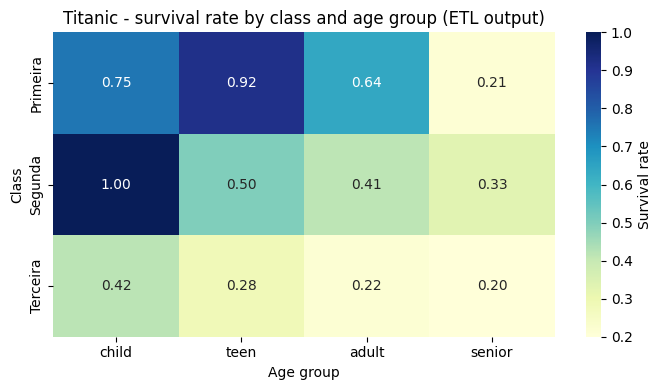

In [25]:
# Quick visual of the ETL result: survival rate by class and age group
import matplotlib.pyplot as plt

pivot = reloaded_json.pivot(index="classe_pt", columns="age_group", values="survival_rate")
pivot = pivot.reindex(index=["Primeira", "Segunda", "Terceira"], columns=["child", "teen", "adult", "senior"])

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "Survival rate"})
ax.set_title("Titanic - survival rate by class and age group (ETL output)")
ax.set_xlabel("Age group")
ax.set_ylabel("Class")
plt.tight_layout()
plt.show()

### 🗂️ Comparação de formatos

Para fechar, vamos comparar tamanho de arquivo e preservação de tipos dos formatos usados.

In [26]:
def format_report(df: pd.DataFrame, out_dir: Path) -> pd.DataFrame:
    """Save df in several formats and report file size and dtype preservation."""
    writers = {
        "csv": (lambda p: df.to_csv(p, index=False), lambda p: pd.read_csv(p)),
        "json": (lambda p: df.to_json(p, orient="records"), lambda p: pd.read_json(p)),
        "jsonl.gz": (lambda p: df.to_json(p, orient="records", lines=True, compression="gzip"),
                     lambda p: pd.read_json(p, lines=True, compression="gzip")),
        "xlsx": (lambda p: df.to_excel(p, index=False), lambda p: pd.read_excel(p)),
    }
    rows = []
    for ext, (write, read) in writers.items():
        path = out_dir / f"format_test.{ext}"
        write(path)
        back = read(path)
        same = (back.dtypes.astype(str) == df.dtypes.astype(str)).mean()
        rows.append({"format": ext, "size_kb": round(path.stat().st_size / 1024, 1), "dtypes_preserved": f"{same:.0%}"})
    return pd.DataFrame(rows).sort_values("size_kb")


format_report(tips, WORK_DIR)

,format,size_kb,dtypes_preserved
2,jsonl.gz,2.0,43%
0,csv,7.8,43%
3,xlsx,12.3,43%
1,json,23.0,43%


---
## 📝 Resumo e Conclusões

### O que aprendi hoje

| Formato | Ler | Escrever | Pontos de atenção |
|---|---|---|---|
| **CSV** | `pd.read_csv` | `df.to_csv` | não preserva tipos; cuidado com `sep`, `decimal`, `encoding`, `na_values` |
| **JSON** | `pd.read_json` | `df.to_json` | escolher `orient`; `lines=True` para JSON Lines; `json_normalize` para aninhados |
| **Excel** | `pd.read_excel` | `df.to_excel` / `ExcelWriter` | múltiplas abas; `sheet_name=None` lê tudo; formatação via `openpyxl` |

### Boas práticas

1. ✅ Use `index=False` ao salvar, salvo quando o índice tem significado.
2. ✅ Declare `encoding="utf-8"` (ou `utf-8-sig` para abrir no Excel) — fundamental para textos em português.
3. ✅ Defina `dtype` e `usecols` para economizar memória (redução de mais de 50% no `titanic`).
4. ✅ Use `chunksize` para arquivos maiores que a memória e agregue resultados parciais.
5. ✅ Valide sempre o *round-trip* (salvar → reler → comparar) em pipelines.
6. ✅ Organize o código em funções `extract` → `transform` → `load` — testáveis e reutilizáveis.

### 🔗 Conexão com PLN aplicado à educação

- Corpora de redações e produções de alunos frequentemente chegam em **JSON Lines** (um texto por linha).
- Metadados de turmas e níveis CEFR costumam vir em **planilhas Excel** de professores.
- Encoding correto é **inegociável** quando lidamos com acentos e caracteres de diferentes línguas.

### 🚀 Próximos passos

- Formatos colunares (**Parquet**, **Feather**) e leitura de bancos de dados com `pd.read_sql`.
- Leitura de dados diretamente de APIs (`requests` + `json_normalize`).
- Aplicar o pipeline ETL a um corpus textual real de aprendizes de inglês.